#### [PREV](2.OOP_Multi_Feature_Linear_Regression.ipynb) | [HOME](../README.md) | [NEXT](4.OOP_Logistic_Regression.ipynb)

---

# OOP Polynomial Linear Regression Implementation

This Jupyter Notebook provides a basic implementation of Polynomial Linear Regression. The data set contains measurements on a single species of insect captured on two continents. We want to predict an insect's wing size given the other measurements we have (continent, latitude and sex).

#### Step 1: Import Dependencies

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error

#### Step 2: Import And Visualise The Data

In [2]:
# Import data as a Pandas DataFrame
insects = pd.read_csv('./data/insects.csv', sep='\t')
insects = pd.DataFrame({
    'continent': insects['continent'],
    'latitude': insects['latitude'],
    'sex': insects['sex'],
    'wingsize': insects['wingsize']
})

# Features variable
X_insects = insects[['continent', 'latitude', 'sex']]
# Target variable
y_insects = insects['wingsize']

insects.head()

,continent,latitude,sex,wingsize
0,1,35.5,0,901
1,1,37.0,0,896
2,1,38.6,0,906
3,1,40.7,0,907
4,1,40.9,0,898


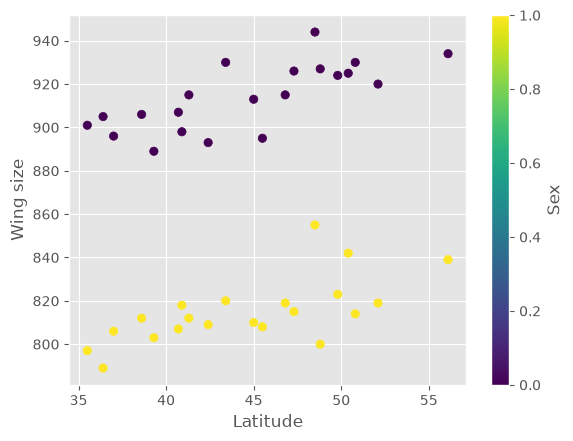

In [3]:
# Plot the data, colour coded by sex
plt.scatter(insects.latitude, insects.wingsize, c=insects['sex'])
plt.xlabel("Latitude")
plt.ylabel("Wing size")
plt.colorbar(label="Sex")
plt.show()

#### Step 3: Instantiate a LinearRegression Object

In [4]:
insects_regression = LinearRegression()

#### Step 4: Fit the model

In [5]:
# Create polynomial features up to degree 4
poly = PolynomialFeatures(degree=4, include_bias=False)

# Fit and transform the features
poly_features = poly.fit_transform(X_insects)

# Fit the regression model
insects_regression.fit(poly_features, y_insects)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](34,)","[ 0. ,-0.01, 0. ,...,-0.08, 0.04, 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,925.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,34
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,9
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](34,)","[13760055.56, 321192.68, 305115.14,..., 0. , 0. , 0. ]"


#### Step 5: Predict Values

In [6]:
# Predict the target for the whole dataset
wing_size_predictions = insects_regression.predict(poly_features)

# Predict the target for a new data point
new_insect = pd.DataFrame({
    'continent': [1],
    'latitude': [40],
    'sex': [0]
})
# Use transform (not fit_transform) so the new data gets the same polynomial features as the training data
new_poly_features = poly.transform(new_insect)
new_insect['wingsize'] = insects_regression.predict(new_poly_features)
print(f"New insect is:\n{new_insect}")

New insect is:
   continent  latitude  sex   wingsize
0          1        40    0  902.81961


#### Step 6: Plot the Predictions

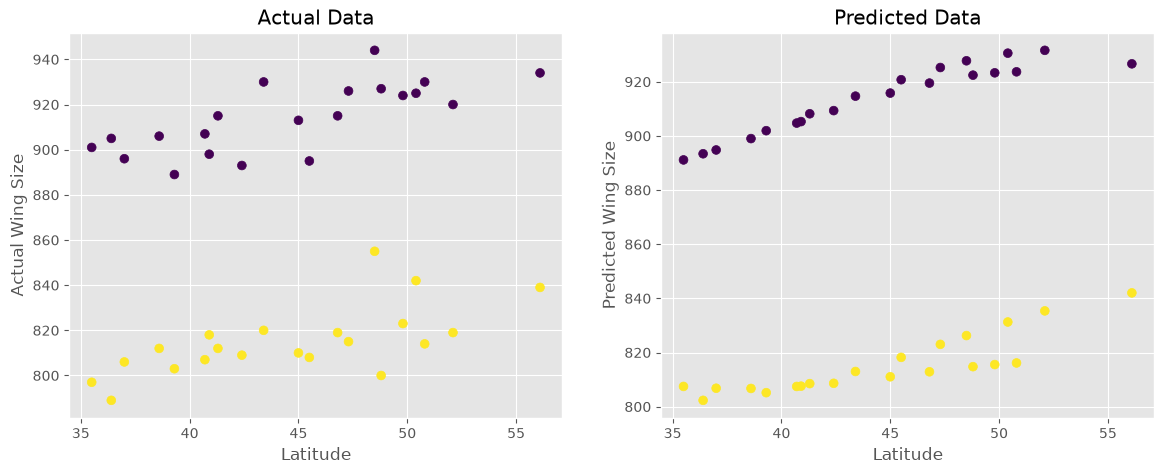

In [7]:
# Plot the predictions compared to the actual data
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(insects.latitude, insects.wingsize, c=insects['sex'], s=40)
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Actual Wing Size")

axs[1].scatter(insects.latitude, wing_size_predictions, c=insects['sex'], s=40)
axs[1].set_title("Predicted Data")
axs[1].set_xlabel("Latitude")
axs[1].set_ylabel("Predicted Wing Size")

plt.show()

#### Step 7: Evaluate The Model

In [8]:
# Get evaluative data from the model
print(f"Model coefficients: {insects_regression.coef_}")
print(f"Model y intercept: {insects_regression.intercept_}")
print(f"Model score (R squared): {insects_regression.score(poly_features, y_insects)}")
mae = mean_absolute_error(y_true=y_insects, y_pred=wing_size_predictions)
mse = mean_squared_error(y_true=y_insects, y_pred=wing_size_predictions)
print("MAE:", mae)
print("MSE:", mse)

Model coefficients: [ 1.72356861e-03 -9.75075176e-03  3.02539795e-03  1.72356861e-03
  2.41345849e-02  1.43024234e-02 -2.92543796e-01  4.24291493e-02
  3.02539795e-03  1.72356861e-03  2.41345849e-02  1.43024234e-02
  1.71167407e-03  2.99693494e-01  1.43024234e-02  1.13653625e-02
 -7.59262435e-02  4.24291493e-02  3.02539795e-03  1.72356861e-03
  2.41345849e-02  1.43024234e-02  1.71167407e-03  2.99693494e-01
  1.43024234e-02 -1.50971648e-04 -2.11660722e-02  2.99693494e-01
  1.43024234e-02 -1.09457977e-04  2.18714746e-03 -7.59262435e-02
  4.24291493e-02  3.02539795e-03]
Model y intercept: 925.390719512486
Model score (R squared): 0.9599490479538307
MAE: 8.076664618133984
MSE: 106.84685821064306


In [9]:
# Optional: Manually evaluate the loss and cost of the model
model_loss = pd.DataFrame({
    'Target': y_insects,
    'Predicted result': wing_size_predictions.round(2),
    'Loss': (wing_size_predictions - y_insects) ** 2  # Squared error for each insect
})
# Cost = 1/(2m) x the sum of the squared errors (half of the MSE printed above)
model_cost = 1 / (2 * model_loss.shape[0]) * model_loss['Loss'].sum()

print(f"The cost of this model is {model_cost:.5f}")
print(model_loss)

The cost of this model is 53.42343
    Target  Predicted result        Loss
0      901            891.13   97.366939
1      896            894.81    1.414793
2      906            899.01   48.850742
3      907            904.74    5.112728
4      898            905.29   53.091890
5      893            909.34  267.009000
6      913            915.81    7.914883
7      915            919.51   20.353077
8      927            922.44   20.792801
9      924            923.30    0.490189
10     930            923.67   40.011697
11     905            893.41  134.414100
12     889            901.93  167.186258
13     915            908.18   46.550041
14     930            914.69  234.470431
15     895            920.75  663.290765
16     926            925.26    0.544647
17     944            927.75  264.083681
18     925            930.56   30.947776
19     920            931.61  134.754205
20     934            926.62   54.399580
21     797            807.47  109.628996
22     806            